# 🧮 02 · The Matrix-Form Forward Pass

> **Module 02 – Feed-Forward Networks and Backpropagation** · Notebook 2 of 6
> Course notes: page 8, $\ o^{h1}=\sigma(W^{h1}x+b^{h1}),\ \  o^{h2}=\sigma(W^{h2}o^{h1}+b^{h2}),\ \  o^{o}=\sigma(W^{o}o^{h2}+b^{o})$

The **forward pass** is how a network turns an input into an output. Neuron by neuron it is just "weighted sum, then activation", but written with **matrices** it becomes one line per layer – and that line runs thousands of times faster and works on GPUs.

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | One neuron = one dot product; one layer = one matrix-vector product |
| 2 | Why $W^{[l]}$ has shape $n_l\times n_{l-1}$ and how shapes chain through the network |
| 3 | Activation functions (sigmoid, tanh, ReLU) and softmax |
| 4 | Processing a whole **batch** at once, and why it is ~1000× faster than loops |
| 5 | A forward pass that keeps a **cache** for backpropagation |
| 6 | A worked 2-2-1 example you can check with pen and paper |
| 7 | What a layer *does* geometrically: it bends space |

## 0 · Setup

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)

---
## 1 · The variables

### 📖 Notation for the whole of module 02 (same as the course notes)

| Symbol | Shape | Meaning |
|---|---|---|
| $L$ | number | number of layers with weights (hidden + output). The input is "layer 0". |
| $n_l$ | number | number of neurons in layer $l$ ($n_0$ = number of inputs) |
| $\vec x = o^{[0]}$ | $n_0\times1$ | one input example, a **column** vector |
| $w_{ji}$ | number | weight on the wire **from** neuron $i$ (layer $l-1$) **to** neuron $j$ (layer $l$). First index = destination. |
| $W^{[l]}$ | $n_l\times n_{l-1}$ | all weights of layer $l$; **row $j$** = the incoming weights of neuron $j$ (notes: $W^{h1}_{5\times4}$) |
| $b^{[l]}$ | $n_l\times1$ | biases of layer $l$, one per neuron (the weight of the constant input $x_0=1$) |
| $net^{[l]}=W^{[l]}o^{[l-1]}+b^{[l]}$ | $n_l\times1$ | net inputs of layer $l$; entry $j$ is $net_j=\sum_i w_{ji}\ o_i+b_j$ |
| $o^{[l]}=g(net^{[l]})$ | $n_l\times1$ | outputs (activations) of layer $l$; $g$ = activation function, e.g. sigmoid |
| $x_{ji}$ | number | the input that arrives at neuron $j$ from $i$, i.e. $x_{ji}=o_i$ (Mitchell / notes) |
| $t_k$ | number | target for output neuron $k$ |
| $E$ | number | the error (loss) we minimise |
| $\delta_j=-\dfrac{\partial E}{\partial net_j}$ | number | **error term** of neuron $j$ ("how much the error drops if $net_j$ rises") |
| $\eta$ | number | learning rate |
| $N$ | number | batch size; a batch is $X\in\mathbb R^{n_0\times N}$ with **one example per column** |

The notes also name layers by role: $h1$, $h2$ (hidden) and $o$ (output), e.g. $o^{h1}=\sigma(W^{h1}x+b^{h1})$.
---
## 2 · One neuron = one dot product

Neuron $j$ in layer $l$ receives the outputs $o_1,\dots,o_{n_{l-1}}$ of the previous layer:

$$net_j=\sum_{i=1}^{n_{l-1}}w_{ji}\ o_i+b_j\qquad\qquad o_j=g(net_j)$$

The sum is a dot product between **row $j$ of $W$** (the neuron's weights) and the input vector.

In [2]:
o_prev = np.array([1.0, 0.5, -1.0])        # outputs of the previous layer (n_{l-1} = 3)
w_j = np.array([0.2, -0.4, 0.1])           # incoming weights of neuron j
b_j = 0.3                                  # its bias

net_loop = 0.0
for i in range(len(o_prev)):               # Σ_i w_ji o_i, written out
    net_loop += w_j[i] * o_prev[i]
net_loop += b_j

net_dot = w_j @ o_prev + b_j               # the same thing as one dot product
print(f"loop: {net_loop:.3f}    dot product: {net_dot:.3f}")

loop: 0.200    dot product: 0.200


---
## 3 · One layer = one matrix-vector product

Stack the weight rows of all $n_l$ neurons into a matrix and all biases into a vector:

$$\underbrace{\begin{bmatrix}net_1\cr  net_2\cr  \vdots\cr  net_{n_l}\end{bmatrix}}_{net^{[l]}\ (n_l\times1)} = \underbrace{\begin{bmatrix}w_{11}&w_{12}&\cdots&w_{1,n_{l-1}}\cr  w_{21}&w_{22}&\cdots&w_{2,n_{l-1}}\cr  \vdots&&&\vdots\cr  w_{n_l1}&\cdots&&w_{n_l,n_{l-1}}\end{bmatrix}}_{W^{[l]}\ (n_l\times n_{l-1})} \underbrace{\begin{bmatrix}o_1\cr  \vdots\cr  o_{n_{l-1}}\end{bmatrix}}_{o^{[l-1]}} + \underbrace{\begin{bmatrix}b_1\cr  \vdots\cr  b_{n_l}\end{bmatrix}}_{b^{[l]}} \qquad \boxed{net^{[l]}=W^{[l]}o^{[l-1]}+b^{[l]},\quad o^{[l]}=g\big(net^{[l]}\big)}$$

**Shape rule:** $(n_l\times n_{l-1})\cdot(n_{l-1}\times1)=(n_l\times1)$. The inner sizes must match; the outer sizes give the result.

The picture below shows the first layer of the notes' 4-5-3-2 network: **row $j$ of $W^{h1}$ times $x$ gives $net_j$**.

check neuron 2 by hand: 0.75 = 0.75


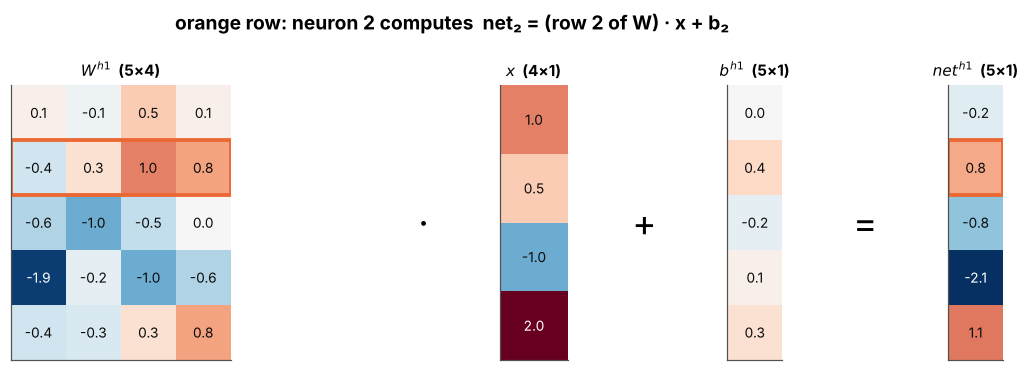

In [3]:
def show_matvec(W, x, b, title=""):
    """Visualise net = W x + b with annotated heat-maps, highlighting one row (neuron 2)."""
    net = W @ x + b
    mats = [W, "·", x, "+", b, "=", net]
    names = ["$W^{h1}$  (5×4)", "", "$x$  (4×1)", "", "$b^{h1}$  (5×1)", "", "$net^{h1}$  (5×1)"]
    fig, axs = plt.subplots(1, 7, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[4, 0.6, 1, 0.6, 1, 0.6, 1]))
    for ax, M, name in zip(axs, mats, names):
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if isinstance(M, str):                                   # an operator symbol
            ax.axis("off"); ax.text(0.5, 0.5, M, fontsize=24, ha="center", va="center"); continue
        ax.imshow(M, cmap="RdBu_r", vmin=-2, vmax=2)
        for (r, c), v in np.ndenumerate(M):
            ax.text(c, r, f"{v + 0.0:.1f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 1.3 else C["ink"])
        ax.set_title(name, fontsize=10)
    for ax in (axs[0], axs[6]):                                  # highlight neuron j = 2 (row index 1)
        ax.add_patch(plt.Rectangle((-0.5, 0.5), ax.get_xlim()[1] + 0.5, 1, fill=False, ec=C["orange"], lw=2.5))
    fig.suptitle(title, fontweight="bold"); plt.tight_layout(); plt.show()
    return net

W_h1 = np.round(rng.normal(0, 0.8, (5, 4)), 1) + 0.0
x = np.array([[1.0], [0.5], [-1.0], [2.0]])
b_h1 = np.round(rng.normal(0, 0.3, (5, 1)), 1) + 0.0
net_h1 = show_matvec(W_h1, x, b_h1, "orange row: neuron 2 computes  net₂ = (row 2 of W) · x + b₂")
print(f"check neuron 2 by hand: {W_h1[1] @ x[:, 0] + b_h1[1, 0]:.2f} = {net_h1[1, 0]:.2f}")

### Shapes through the whole 4-5-3-2 network (notes, page 8)

| layer | computation | shapes |
|---|---|---|
| h1 | $o^{h1}=\sigma(W^{h1}x+b^{h1})$ | $(5\times4)(4\times1)+(5\times1)\to 5\times1$ |
| h2 | $o^{h2}=\sigma(W^{h2}o^{h1}+b^{h2})$ | $(3\times5)(5\times1)+(3\times1)\to 3\times1$ |
| o | $o^{o}=\sigma(W^{o}o^{h2}+b^{o})$ | $(2\times3)(3\times1)+(2\times1)\to 2\times1$ |

Notice how the **output size of one layer is the input size of the next** – the shapes chain like dominoes.

---
## 4 · Activation functions $g$

From module 01: without a non-linear $g$, the layers collapse into one. Common choices:

| name | $g(z)$ | $g'(z)$ | output range |
|---|---|---|---|
| sigmoid (notes) | $\dfrac1{1+e^{-z}}$ | $g(1-g)$ | $(0,1)$ |
| tanh | $\dfrac{e^z-e^{-z}}{e^z+e^{-z}}$ | $1-g^2$ | $(-1,1)$ |
| ReLU | $\max(0,z)$ | $1$ if $z>0$ else $0$ | $[0,\infty)$ |

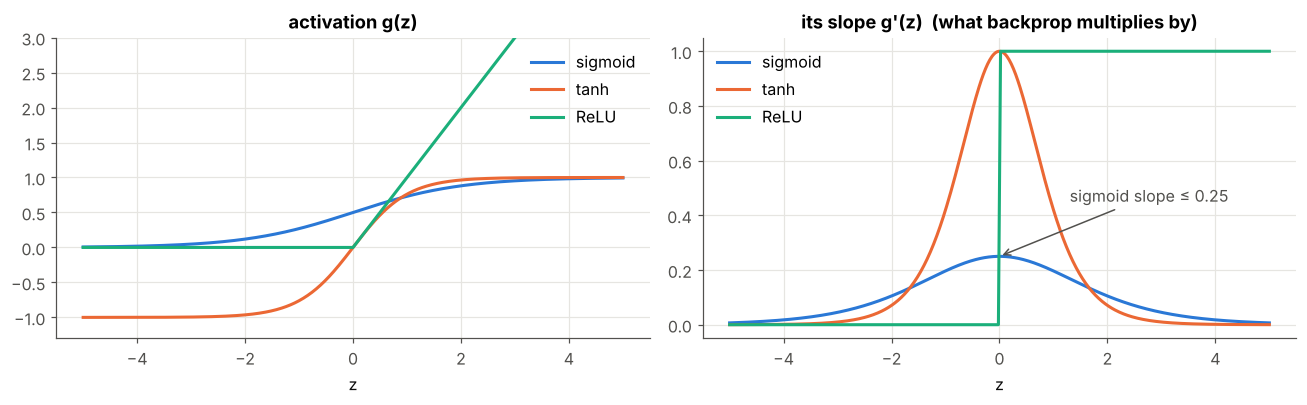

In [4]:
def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))
def tanh(z):    return np.tanh(z)
def relu(z):    return np.maximum(0.0, z)

zs = np.linspace(-5, 5, 501)
acts = [("sigmoid", sigmoid, C["blue"]), ("tanh", tanh, C["orange"]), ("ReLU", relu, C["aqua"])]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for name, f, col in acts:
    axs[0].plot(zs, f(zs), color=col, label=name)
    h = 1e-5
    axs[1].plot(zs, (f(zs + h) - f(zs - h)) / (2 * h), color=col, label=name)   # numerical derivative
axs[0].set_ylim(-1.3, 3); axs[0].set_title("activation g(z)"); axs[0].legend(); axs[0].set_xlabel("z")
axs[1].set_title("its slope g'(z)  (what backprop multiplies by)"); axs[1].legend(); axs[1].set_xlabel("z")
axs[1].annotate("sigmoid slope ≤ 0.25", xy=(0, 0.25), xytext=(1.3, 0.45), arrowprops=dict(arrowstyle="->", color=C["muted"]), color=C["muted"])
plt.tight_layout(); plt.show()

---
## 5 · A whole batch at once 📦

To push $N$ examples through a layer, put them side by side as **columns** of a matrix $X\in\mathbb R^{n_0\times N}$:

$$\boxed{NET^{[l]}=W^{[l]}\ O^{[l-1]}+b^{[l]}}\qquad (n_l\times n_{l-1})\cdot(n_{l-1}\times N)=(n_l\times N)$$

Column $n$ of the result is exactly the single-example computation for example $n$. The bias $b^{[l]}$ ($n_l\times1$) is **broadcast**: NumPy adds it to every column. $N$ never appears in $W$ or $b$ – the same weights are reused for every example.

In [5]:
def dense(O_prev, W, b):
    """One layer for a whole batch: (n_l × n_{l-1}) @ (n_{l-1} × N) + (n_l × 1) → (n_l × N)."""
    return W @ O_prev + b

def dense_loops(O_prev, W, b):
    """The same layer with explicit Python loops (slow, for comparison)."""
    n_out, n_in = W.shape
    N = O_prev.shape[1]
    NET = np.zeros((n_out, N))
    for n in range(N):                    # every example
        for j in range(n_out):            # every neuron
            s = 0.0
            for i in range(n_in):         # every incoming wire
                s += W[j, i] * O_prev[i, n]
            NET[j, n] = s + b[j, 0]
    return NET

X = rng.normal(size=(4, 6))               # 6 examples, 4 features each (one per column)
print("W_h1", W_h1.shape, "@ X", X.shape, "+ b", b_h1.shape, "→", dense(X, W_h1, b_h1).shape)
assert np.allclose(dense(X, W_h1, b_h1), dense_loops(X, W_h1, b_h1))
assert np.allclose(dense(X, W_h1, b_h1)[:, [2]], W_h1 @ X[:, [2]] + b_h1)   # column 2 = example 2 alone
print("matrix version == loop version, and column n == example n alone ✅")

W_h1 (5, 4) @ X (4, 6) + b (5, 1) → (5, 6)
matrix version == loop version, and column n == example n alone ✅


In [6]:
timings = {}
for (n_in, n_out, N) in [(64, 32, 16), (256, 64, 32), (512, 128, 64)]:
    Xb, Wb, bb = rng.normal(size=(n_in, N)), rng.normal(size=(n_out, n_in)), np.zeros((n_out, 1))
    t0 = time.perf_counter(); dense_loops(Xb, Wb, bb); t_loop = time.perf_counter() - t0
    t0 = time.perf_counter()
    for _ in range(100): dense(Xb, Wb, bb)
    t_mat = (time.perf_counter() - t0) / 100
    timings[f"{n_out}×{n_in} layer\nbatch {N}"] = (t_loop, t_mat)
    print(f"W {n_out}×{n_in}, batch {N:>3}:  loops {t_loop * 1e3:9.2f} ms | matrix {t_mat * 1e3:7.4f} ms | ≈ {t_loop / t_mat:,.0f}× faster")

W 32×64, batch  16:  loops      8.48 ms | matrix  0.0054 ms | ≈ 1,556× faster
W 64×256, batch  32:  loops    129.10 ms | matrix  0.0257 ms | ≈ 5,030× faster
W 128×512, batch  64:  loops    728.94 ms | matrix  0.1083 ms | ≈ 6,730× faster


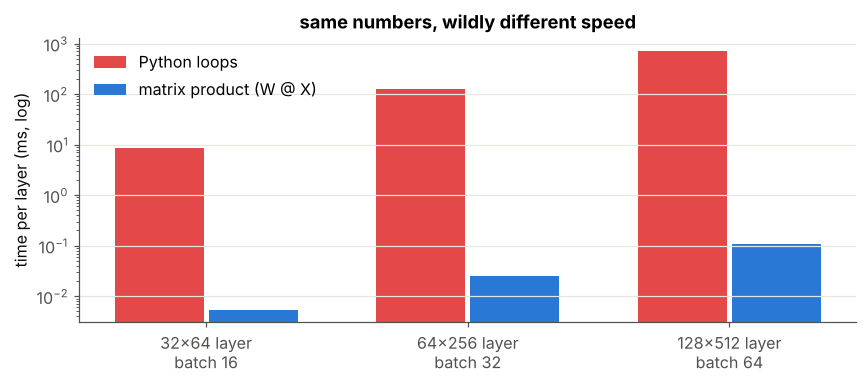

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
labels = list(timings); xx = np.arange(len(labels))
ax.bar(xx - 0.18, [v[0] * 1e3 for v in timings.values()], 0.34, color=C["red"], label="Python loops")
ax.bar(xx + 0.18, [v[1] * 1e3 for v in timings.values()], 0.34, color=C["blue"], label="matrix product (W @ X)")
ax.set_yscale("log"); ax.set_xticks(xx, labels); ax.set_ylabel("time per layer (ms, log)")
ax.set_title("same numbers, wildly different speed"); ax.legend(); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

The matrix form hands the work to optimised linear-algebra libraries (BLAS), and later to GPUs, which are built for exactly this operation.

---
## 6 · Softmax: turning output scores into probabilities 🎲

For classification with $K$ classes we want the outputs to be **probabilities** (positive, summing to 1). Softmax does that (the notes introduce it for word2vec, page 10):

$$p_k=\text{softmax}(z)_k=\frac{e^{z_k}}{\sum_{m=1}^{K}e^{z_m}}$$

* $z_k$: the **score** (net input) of output neuron $k$; $K$: number of classes; $p_k$: probability of class $k$.
* $e^{z}$ makes every score positive; dividing by the sum makes them add to 1; a bigger score always gets a bigger probability.

**Numerical trick:** $e^{1000}$ overflows. Since softmax doesn't change if we subtract the same constant from every $z_k$, we subtract the max first.

scores z       : [ 2.   1.   0.1 -1. ]
softmax(z)     : [0.6381 0.2347 0.0954 0.0318]  sum = 1.0
naive  on big z: [nan nan nan]  ← overflow → nan
stable on big z: [0.09   0.2447 0.6652]


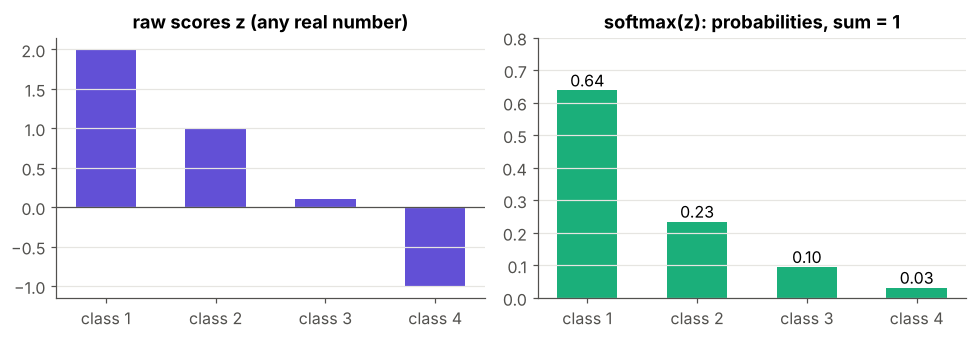

In [8]:
def softmax(Z):
    """Column-wise softmax (each column = one example). Subtract the max for numerical stability."""
    Z = Z - Z.max(axis=0, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=0, keepdims=True)

z = np.array([[2.0], [1.0], [0.1], [-1.0]])
p = softmax(z)
print("scores z       :", z.ravel())
print("softmax(z)     :", p.ravel().round(4), " sum =", p.sum())

big = np.array([[1000.0], [1001.0], [1002.0]])
with np.errstate(all="ignore"):
    naive = np.exp(big) / np.exp(big).sum()
print("naive  on big z:", naive.ravel(), " ← overflow → nan")
print("stable on big z:", softmax(big).ravel().round(4))

fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
cls = ["class 1", "class 2", "class 3", "class 4"]
axs[0].bar(cls, z.ravel(), color=C["violet"], width=0.55); axs[0].axhline(0, color=C["muted"], lw=0.8)
axs[0].set_title("raw scores z (any real number)")
bars = axs[1].bar(cls, p.ravel(), color=C["aqua"], width=0.55); axs[1].bar_label(bars, fmt="%.2f")
axs[1].set_title("softmax(z): probabilities, sum = 1"); axs[1].set_ylim(0, 0.8)
for a in axs: a.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

---
## 7 · The full forward pass, with a cache for backprop 💾

Repeat "matrix product + bias + activation" layer by layer, from $o^{[0]}=X$ to the output. We **store** every $net^{[l]}$ and $o^{[l]}$ in a `cache`, because backpropagation (notebooks 03–04) needs them again.

In [9]:
ACTIVATIONS = {"sigmoid": sigmoid, "tanh": tanh, "relu": relu, "softmax": softmax,
               "identity": lambda z: z}


def init_params(sizes, rng, scale=None):
    """W^[l]: (n_l × n_{l-1}) Gaussian, std = 1/sqrt(n_{l-1}) unless given; b^[l]: zeros (n_l × 1)."""
    return [(rng.normal(0, scale or 1 / np.sqrt(sizes[l - 1]), (sizes[l], sizes[l - 1])),
             np.zeros((sizes[l], 1))) for l in range(1, len(sizes))]


def forward(X, params, hidden="sigmoid", output="sigmoid", verbose=False):
    """X: (n_0 × N), one example per column. Returns final output and cache[l] = (net^[l], o^[l])."""
    O = X
    cache = [(None, X)]                                       # layer 0: no net, o^[0] = X
    L = len(params)
    for l, (W, b) in enumerate(params, start=1):
        NET = W @ O + b                                       # net^[l] = W^[l] o^[l-1] + b^[l]
        g = ACTIVATIONS[output if l == L else hidden]
        O_new = g(NET)                                        # o^[l] = g(net^[l])
        if verbose:
            print(f"layer {l}: W{W.shape} @ o{O.shape} + b{b.shape} → net{NET.shape} "
                  f"--{output if l == L else hidden}--> o{O_new.shape}")
        O = O_new
        cache.append((NET, O))
    return O, cache

In [10]:
print("Notes' network 4-5-3-2, one example:")
params_452 = init_params([4, 5, 3, 2], rng)
o_out, _ = forward(np.array([[1.0], [0.5], [-1.0], [2.0]]), params_452, verbose=True)
print("output o^o =", o_out.ravel())

print("\nMNIST-style network 784-128-64-10, batch of 32, sigmoid hidden + softmax output:")
P, cache = forward(rng.normal(size=(784, 32)), init_params([784, 128, 64, 10], rng),
                   hidden="sigmoid", output="softmax", verbose=True)
print("every column sums to 1:", np.allclose(P.sum(axis=0), 1.0), "| cache holds", len(cache), "entries (layers 0..3)")

Notes' network 4-5-3-2, one example:
layer 1: W(5, 4) @ o(4, 1) + b(5, 1) → net(5, 1) --sigmoid--> o(5, 1)
layer 2: W(3, 5) @ o(5, 1) + b(3, 1) → net(3, 1) --sigmoid--> o(3, 1)
layer 3: W(2, 3) @ o(3, 1) + b(2, 1) → net(2, 1) --sigmoid--> o(2, 1)
output o^o = [0.2772 0.5892]

MNIST-style network 784-128-64-10, batch of 32, sigmoid hidden + softmax output:
layer 1: W(128, 784) @ o(784, 32) + b(128, 1) → net(128, 32) --sigmoid--> o(128, 32)
layer 2: W(64, 128) @ o(128, 32) + b(64, 1) → net(64, 32) --sigmoid--> o(64, 32)
layer 3: W(10, 64) @ o(64, 32) + b(10, 1) → net(10, 32) --softmax--> o(10, 32)
every column sums to 1: True | cache holds 4 entries (layers 0..3)


### 🔍 Code walk-through
| Code | Maths | Note |
|---|---|---|
| `cache = [(None, X)]` | $o^{[0]}=X$ | layer 0 has no $net$ |
| `NET = W @ O + b` | $net^{[l]}=W^{[l]}o^{[l-1]}+b^{[l]}$ | `b` broadcasts over the $N$ columns |
| `O_new = g(NET)` | $o^{[l]}=g(net^{[l]})$ | elementwise (softmax: per column) |
| `cache.append((NET, O))` | store $net^{[l]},o^{[l]}$ | needed by backprop |
| `init_params` | $W\sim\mathcal N(0,1/n_{l-1})$ | keeps $net$ values at a sensible size (more in notebook 04) |

---
## 8 · A worked 2-2-1 example (pen and paper ✍️)

Input $x=\begin{bmatrix}1\cr 0.5\end{bmatrix}$, sigmoid everywhere.
$W^{[1]}=\begin{bmatrix}0.2&0.4\cr -0.3&0.1\end{bmatrix}$ (row 1 = neuron 1's weights), $b^{[1]}=\begin{bmatrix}0.1\cr -0.1\end{bmatrix}$, $\ W^{[2]}=\begin{bmatrix}0.6&-0.2\end{bmatrix}$, $b^{[2]}=0.05$.

| step | computation | value |
|---|---|---|
| $net^{[1]}_1$ | $0.2\cdot1+0.4\cdot0.5+0.1$ | $0.5$ |
| $net^{[1]}_2$ | $-0.3\cdot1+0.1\cdot0.5-0.1$ | $-0.35$ |
| $o^{[1]}$ | $\sigma(0.5),\ \sigma(-0.35)$ | $0.6225,\ 0.4134$ |
| $net^{[2]}$ | $0.6\cdot0.6225-0.2\cdot0.4134+0.05$ | $0.3408$ |
| $o^{[2]}$ | $\sigma(0.3408)$ | $\mathbf{0.5844}$ |

In [11]:
x  = np.array([[1.0], [0.5]])
W1 = np.array([[0.2, 0.4], [-0.3, 0.1]]); b1 = np.array([[0.1], [-0.1]])
W2 = np.array([[0.6, -0.2]]);              b2 = np.array([[0.05]])

net1 = W1 @ x + b1;  o1 = sigmoid(net1)
net2 = W2 @ o1 + b2; o2 = sigmoid(net2)
print("net1 =", net1.ravel(), "  o1 =", o1.ravel().round(4))
print("net2 =", net2.ravel().round(4), "  o2 =", o2.ravel().round(4))
assert np.allclose(net1.ravel(), [0.5, -0.35]) and np.isclose(o2[0, 0], 0.5844, atol=1e-4)

out, _ = forward(x, [(W1, b1), (W2, b2)])                    # the general function agrees
print("forward() gives the same:", out.ravel().round(4))

net1 = [ 0.5  -0.35]   o1 = [0.6225 0.4134]
net2 = [0.3408]   o2 = [0.5844]
forward() gives the same: [0.5844]


---
## 9 · What does a layer *do*? It bends space 🌀

A layer $o=g(Wx+b)$ does two things: the **matrix** $W$ rotates/stretches/shears the input space (straight lines stay straight), and the **activation** $g$ squashes it non-linearly (straight lines become curves). Here is a square grid pushed through a 2→2 tanh layer:

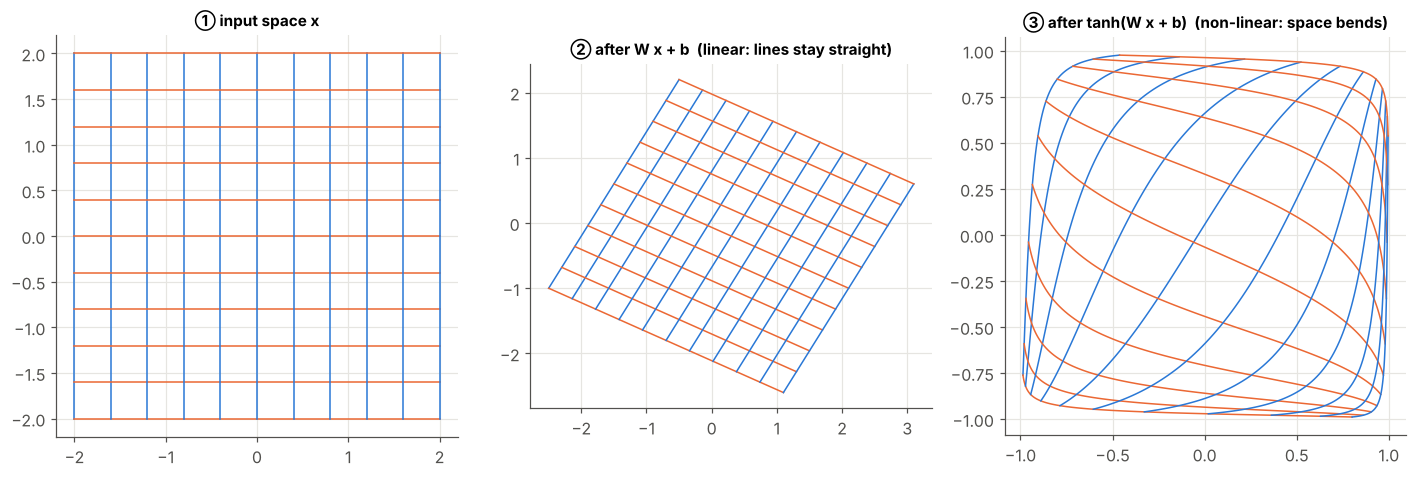

In [12]:
W_demo = np.array([[0.9, 0.5], [-0.4, 0.8]]); b_demo = np.array([[0.3], [-0.2]])
lines = []
for v in np.linspace(-2, 2, 11):
    t = np.linspace(-2, 2, 100)
    lines.append(np.vstack([np.full_like(t, v), t]))         # vertical grid line
    lines.append(np.vstack([t, np.full_like(t, v)]))         # horizontal grid line

fig, axs = plt.subplots(1, 3, figsize=(13, 4.3))
stages = [("① input space x", lambda P: P),
          ("② after W x + b  (linear: lines stay straight)", lambda P: W_demo @ P + b_demo),
          ("③ after tanh(W x + b)  (non-linear: space bends)", lambda P: np.tanh(W_demo @ P + b_demo))]
for ax, (title, f) in zip(axs, stages):
    for k, P in enumerate(lines):
        Q = f(P)
        ax.plot(Q[0], Q[1], color=C["blue"] if k % 2 == 0 else C["orange"], lw=1)
    ax.set_title(title, fontsize=10); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

Stacking such layers lets the network fold the input space until the classes become separable by a straight line at the end – exactly what the hand-built XOR network did in module 01.

---
## 10 · Summary 📌

| Item | Formula | Shape |
|---|---|---|
| one neuron | $net_j=\sum_iw_{ji}o_i+b_j$ | scalar |
| one layer, one example | $net^{[l]}=W^{[l]}o^{[l-1]}+b^{[l]}$, $o^{[l]}=g(net^{[l]})$ | $n_l\times1$ |
| one layer, batch | $NET^{[l]}=W^{[l]}O^{[l-1]}+b^{[l]}$ | $n_l\times N$ |
| softmax | $p_k=e^{z_k}/\sum_m e^{z_m}$ (subtract max first) | $K\times N$ |
| speed | matrix form ≈ 1000× faster than loops | – |

### ✍️ Try it yourself
1. Redo the 2-2-1 example with `tanh` hidden units, by hand then in code.
2. Pass a batch of 1000 examples through `forward`. Which dimensions change? Which never do?
3. Replace the two inner loops of `dense_loops` with `W @ O_prev[:, n] + b[:, 0]` and time it. Where does most of the speed-up come from?
4. Show that `softmax(z + 100)` equals `softmax(z)`. Why does this justify the max-subtraction trick?

**Next →** `03 - Backprop for the Output Layer`